## Шаг 1–2. Обоснование выбора целевой переменной, периода даты и группы
1. **Целевая переменная (`population`)** — численность населения города (в человеках). Это главный непрерывный количественный показатель набора данных `clean.parquet`, вокруг которого строятся демографические задачи и сравнения.
2. **Столбец даты / периода (`1970`–`2022` гг. на основе `1970_population` .. `2022_population`)** — демографическая динамика в наборе данных представлена переписными срезами за 1970–2022 гг. Поскольку ряд охватывает более 50 лет, шаг выбран в **5 лет** (периоды `1970-01-01`, `1975-01-01`, ..., `2020-01-01`, `2022-01-01`). Годы `1975`, `1985`, `1995` и `2005`, в которых переписи в справочнике отсутствуют, оставлены в ряду как **пустые периоды** (`Число записей = 0`, медиана `NaN`), чтобы не скрывать пропуски наблюдений.
3. **Столбец группы (`continent`)** — континент расположения города (`Asia`, `Europe`, `North America`, `Africa`, `South America`, `Oceania`, `Unknown`). Значения повторяются у тысяч городов и делят выборку на географические макрорегионы. Для сводной таблицы второй категорией выбран статус столицы **`capital_x`** (`primary`, `admin`, `minor`, `not_capital`).

In [ ]:
import sys
import os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.eda import (
    target_summary,
    build_time_series,
    group_aggregates,
    build_pivot_table,
    compare_anomalies,
    benchmark_vectorization,
    generate_all_plots,
)

print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__} | numpy: {np.__version__} | matplotlib: {matplotlib.__version__}")

# Читаем очищенный набор из Лабораторной работы № 1
df = pd.read_parquet("../data/processed/clean.parquet")
print("Размер таблицы clean.parquet:", df.shape)

Python: 3.11.2 | pandas: 2.2.3 | numpy: 2.1.3 | matplotlib: 3.10.1
Размер таблицы clean.parquet: (50250, 30)


## Шаг 3. Распределение целевой переменной (`population`)

In [ ]:
table1 = target_summary(df, target_col="population")
display(table1)

,Показатель,Значение
0,Число наблюдений,50250
1,Число пропусков,432
2,Минимум,1.0
3,Первый квартиль,11913.0
4,Медиана,20208.5
5,Среднее,96941.41
6,Третий квартиль,44832.25
7,Максимум,39105000.0
8,Скошенность,Вправо (положительная)


## Шаг 4. Динамика по датам (периодам 1970–2022 гг.)

In [ ]:
table2_full = build_time_series(df, target_col="population")
display(table2_full)

,date,Период,Число записей,Медиана цели,Среднее цели
0,1970-01-01,1970,50170,10979.69,50047.39
1,1975-01-01,1975,0,NaN,NaN
2,1980-01-01,1980,50170,12683.11,59103.18
3,1985-01-01,1985,0,NaN,NaN
4,1990-01-01,1990,50170,14547.34,69098.15
5,1995-01-01,1995,0,NaN,NaN
6,2000-01-01,2000,50170,16339.29,78204.47
7,2005-01-01,2005,0,NaN,NaN
8,2010-01-01,2010,50170,18174.73,87081.90
9,2015-01-01,2015,50170,19056.69,91676.06


## Шаг 5. Агрегаты по группам (`continent`) и сводная таблица
- **Порог редкой категории:** `1%` (`0.01`) от общего числа записей (менее 503 записей из 50 250).
- **Число слитых категорий:** `2` категории (`Oceania` — 443 записи, `0.88%`; `Unknown` — 80 записей, `0.16%`) на столбчатой диаграмме объединены в группу **«Прочие»** (`523` записи), а в Таблице 3 оставлены отдельными строками.

In [ ]:
table3, plot_agg, rare_groups = group_aggregates(df, group_col="continent", target_col="population", rare_threshold=0.01)
print("Редкие категории (< 1%), слитые на графике в 'Прочие':", rare_groups)
display(table3)

print("\nСводная таблица (строки — континент, столбцы — статус столицы capital_x, ячейка — медиана населения):")
pivot_df = build_pivot_table(df, row_col="continent", col_col="capital_x", target_col="population")
display(pivot_df)

Редкие категории (< 1%), слитые на графике в 'Прочие': ['Oceania', 'Unknown']


,Группа,Число,Медиана,Среднее,Доля пропусков
0,Asia,17084,23808.0,150584.75,1.41%
1,Europe,13128,16440.5,49463.82,0.48%
2,North America,8412,20118.5,74515.41,0.14%
3,Africa,5741,21153.0,101012.62,1.65%
4,South America,5362,22090.5,76194.37,0.17%
5,Oceania,443,10999.0,69140.12,2.03%
6,Unknown,80,17788.5,42940.02,3.75%



Сводная таблица (строки — континент, столбцы — статус столицы capital_x, ячейка — медиана населения):


capital_x,primary,admin,minor,not_capital
continent,,,,
Africa,989318.0,58654.5,74165.0,18839.0
Asia,2300500.0,104011.0,35544.5,21451.5
Europe,615764.0,20208.5,21551.0,14709.0
North America,31196.0,99802.5,24201.5,18905.5
Oceania,24937.5,17484.5,NaN,10259.0
South America,1788170.0,188003.0,22051.0,18112.0
Unknown,2458.5,13092.0,NaN,26009.0


## Шаг 6. Поиск и сопоставление аномалий двумя правилами
До построения рисунка заданы два правила:
1. **Первое правило (межквартильный размах `1.5 * IQR`):** запись считается выбросом, если `population < Q1 - 1.5 * IQR` или `population > Q3 + 1.5 * IQR` (верхний порог составил `94 211.12` чел.).
2. **Второе правило (модуль z-оценки `|z| > 3`):** запись считается аномалией (крупнейшим мегаполисом), если её отклонение от среднего превышает 3 стандартных отклонения (`population > 1 984 243.48` чел.).

In [ ]:
table4, mask_iqr, mask_z, mask_both, upper_iqr, upper_z = compare_anomalies(df, target_col="population")
print(f"Порог 1.5 IQR: {upper_iqr:,.2f} чел. | Порог |z| > 3: {upper_z:,.2f} чел.")
display(table4)

Порог 1.5 IQR: 94,211.12 чел. | Порог |z| > 3: 1,984,243.48 чел.


,Правило,Число отмеченных,Доля,Совпало со вторым
0,Межквартильный размах,6567,13.07%,327
1,Второе правило (|z| > 3),327,0.65%,327
2,Пересечение,327,0.65%,327


## Шаг 7. Векторизация: замер цикла Python и `numpy`

In [ ]:
table5, t_loop, t_np, ratio, val = benchmark_vectorization(df["population"])
display(table5)

,Способ,"Медиана времени, с",Значение метрики
0,Цикл Python,0.003903,96941.42
1,numpy,0.000100,96941.42
2,Отношение цикл / numpy,38.9 раз,96941.42
3,Число значений,50250,—


## Шаг 8. Шесть графиков и выводы под каждым

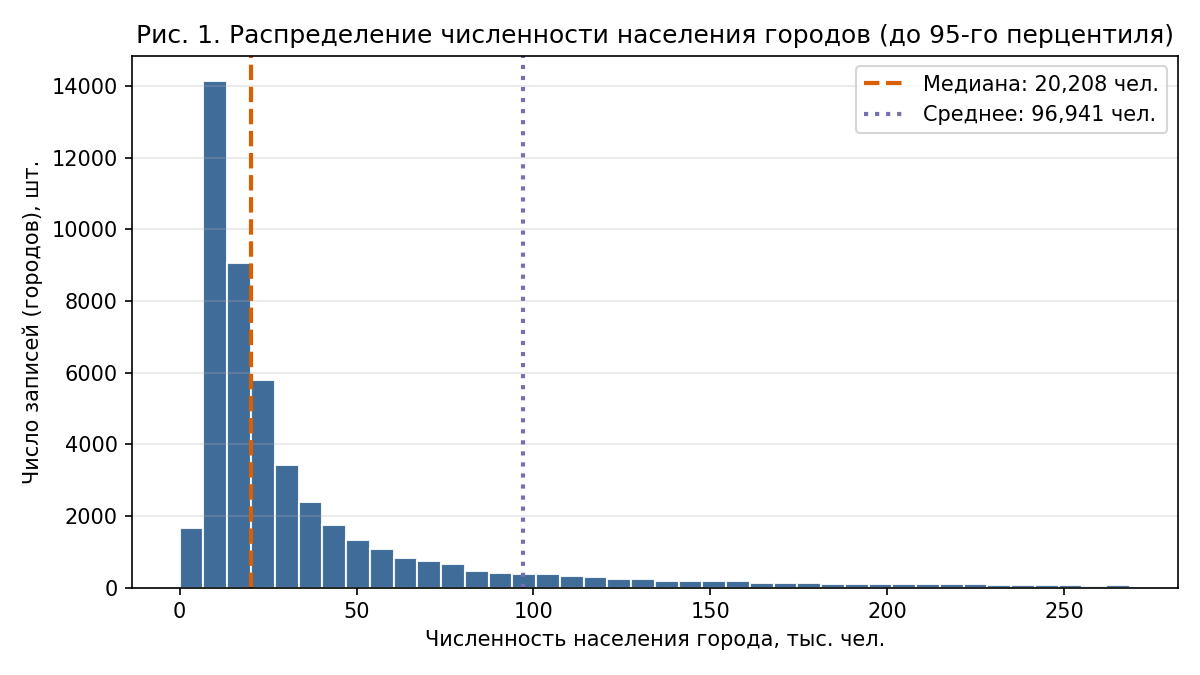

In [ ]:
generate_all_plots(df, plots_dir="../plots")
display(Image(filename="../plots/01_hist.png"))

**Вывод по рисунку 1 (Гистограмма целевой переменной):** Распределение численности населения городов (`population`) сильно скошено вправо: основная масса городов сосредоточена в диапазоне от 10 до 30 тыс. человек (медиана равна `20 208.5` чел.), тогда как из-за длинного правого хвоста мегаполисов среднее арифметическое смещено вверх почти в 4.8 раза — до `96 941.41` чел.

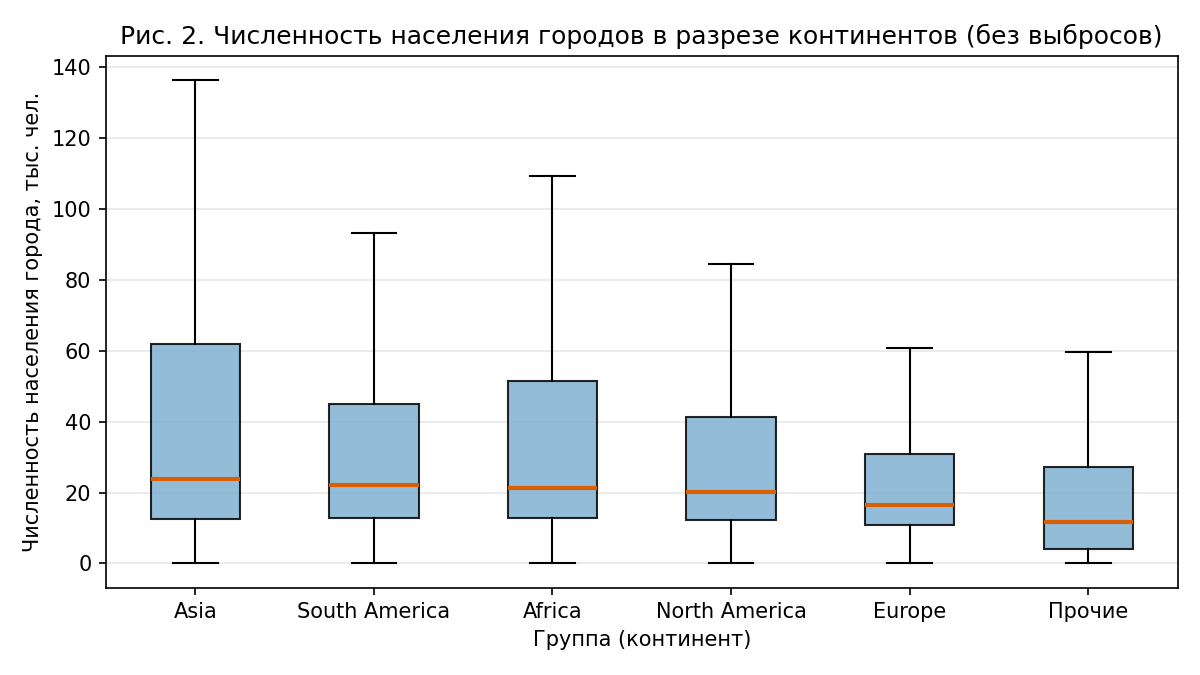

In [ ]:
display(Image(filename="../plots/02_groups_box.png"))

**Вывод по рисунку 2 (Целевая переменная в разрезе групп):** В разрезе континентов наибольший межквартильный размах и самая высокая медиана населения наблюдаются в Азии (`Asia`, медиана `23.8` тыс. чел., третий квартиль свыше `62` тыс. чел.), а наиболее компактное распределение с меньшим типичным размером городов характерно для Европы (`Europe`, медиана `16.4` тыс. чел.) и группы «Прочие» (`11.6` тыс. чел.).

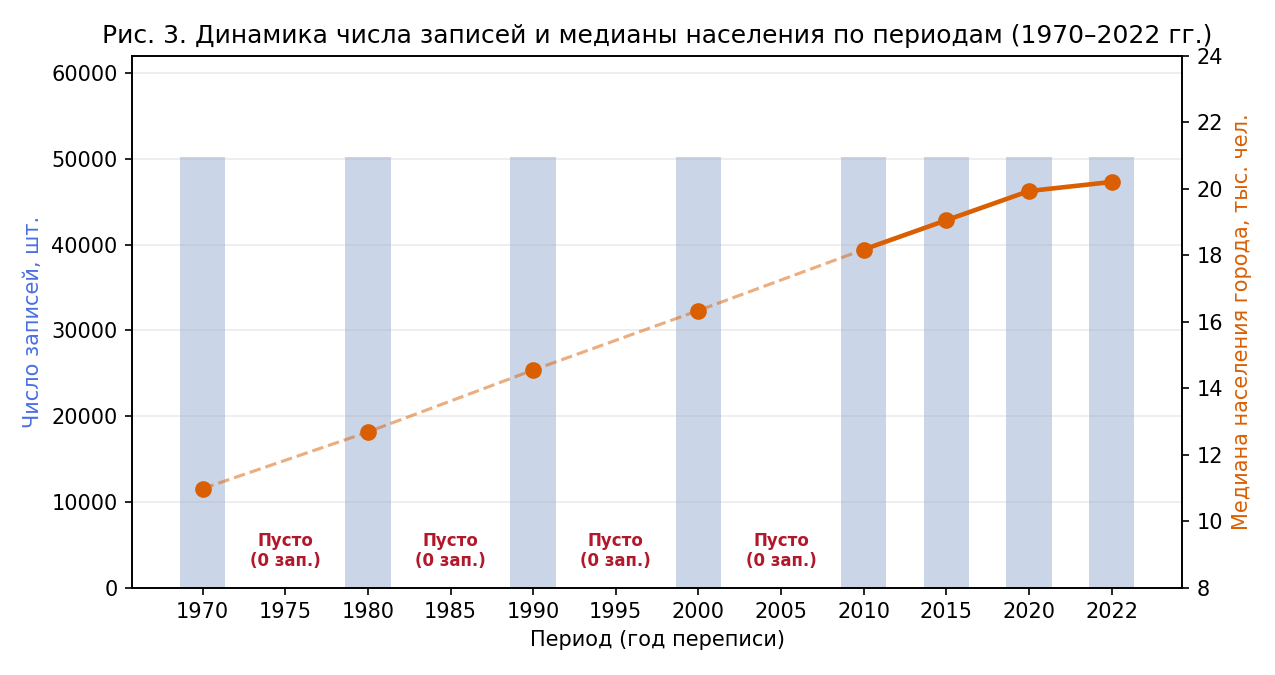

In [ ]:
display(Image(filename="../plots/03_time_series.png"))

**Вывод по рисунку 3 (Ряд по датам):** В промежуточные пятилетние периоды `1975`, `1985`, `1995` и `2005` гг. переписи не проводились, поэтому число записей в них падает до `0`, а линия медианы прерывается. В годы проведения переписей объём выборки стабилен (`50 170` городов), при этом медианная численность населения города монотонно выросла почти вдвое — с `10 979.69` чел. в 1970 году до `20 208.50` чел. в 2022 году.

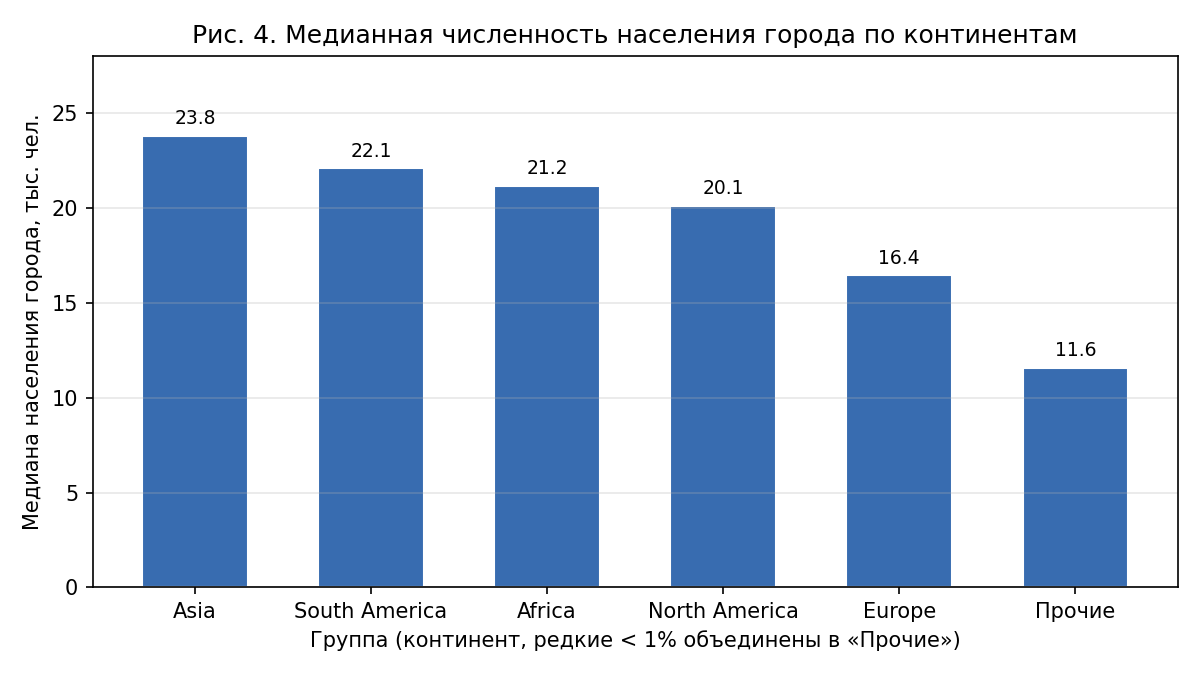

In [ ]:
display(Image(filename="../plots/04_group_bars.png"))

**Вывод по рисунку 4 (Столбчатая диаграмма агрегата по группам):** Лидером по медианной численности населения города является Азия (`Asia` — `23.8` тыс. чел.), за ней следуют Южная Америка (`South America` — `22.1` тыс. чел.) и Африка (`Africa` — `21.2` тыс. чел.), тогда как в Европе (`16.4` тыс. чел.) и объединённой группе редких категорий «Прочие» (`Oceania` и `Unknown`, `11.6` тыс. чел.) преобладают малые населённые пункты.

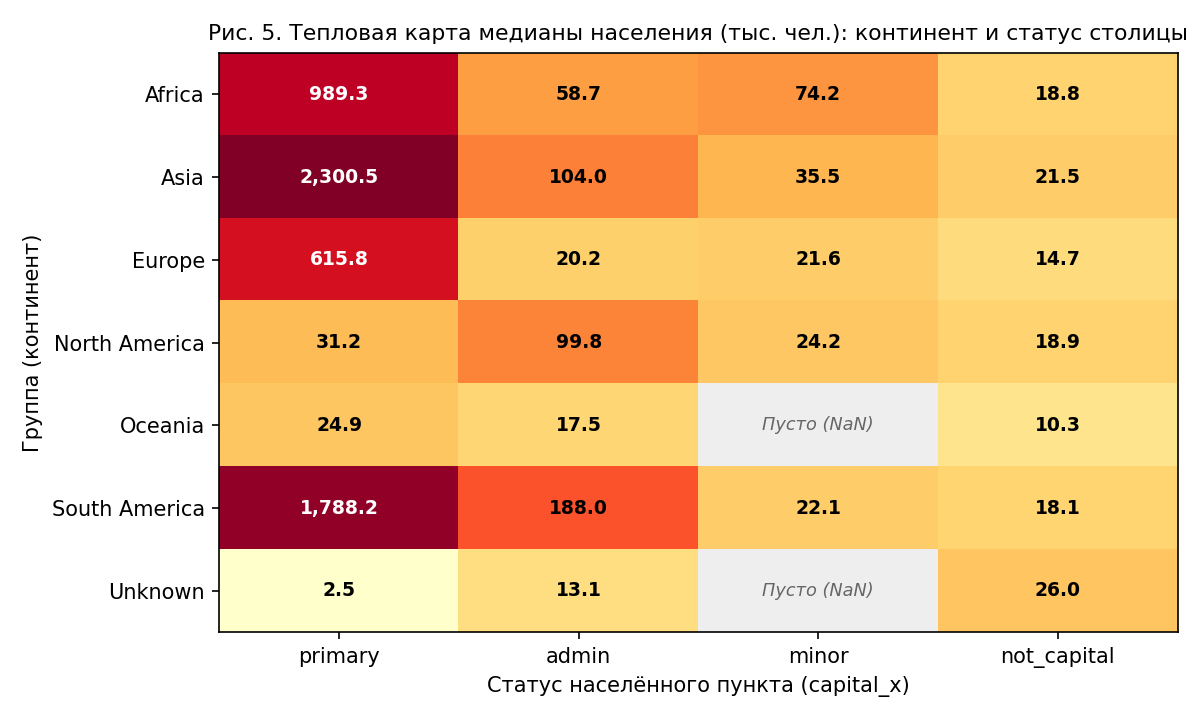

In [ ]:
display(Image(filename="../plots/05_heatmap.png"))

**Вывод по рисунку 5 (Тепловая карта сводной таблицы):** Во всех основных регионах медианное население столиц государств (`primary`) на порядок превышает рядовые города (`not_capital`), достигая максимума в Азии (`2 300.5` тыс. чел.) и Южной Америке (`1 788.2` тыс. чел.). В Северной Америке региональные центры (`admin`, `99.8` тыс. чел.) крупнее столиц (`primary`, `31.2` тыс. чел.) из-за множества малых островных государств Карибского бассейна, а в группах `Oceania` и `Unknown` в категории `minor` записи отсутствуют (`Пусто (NaN)`).

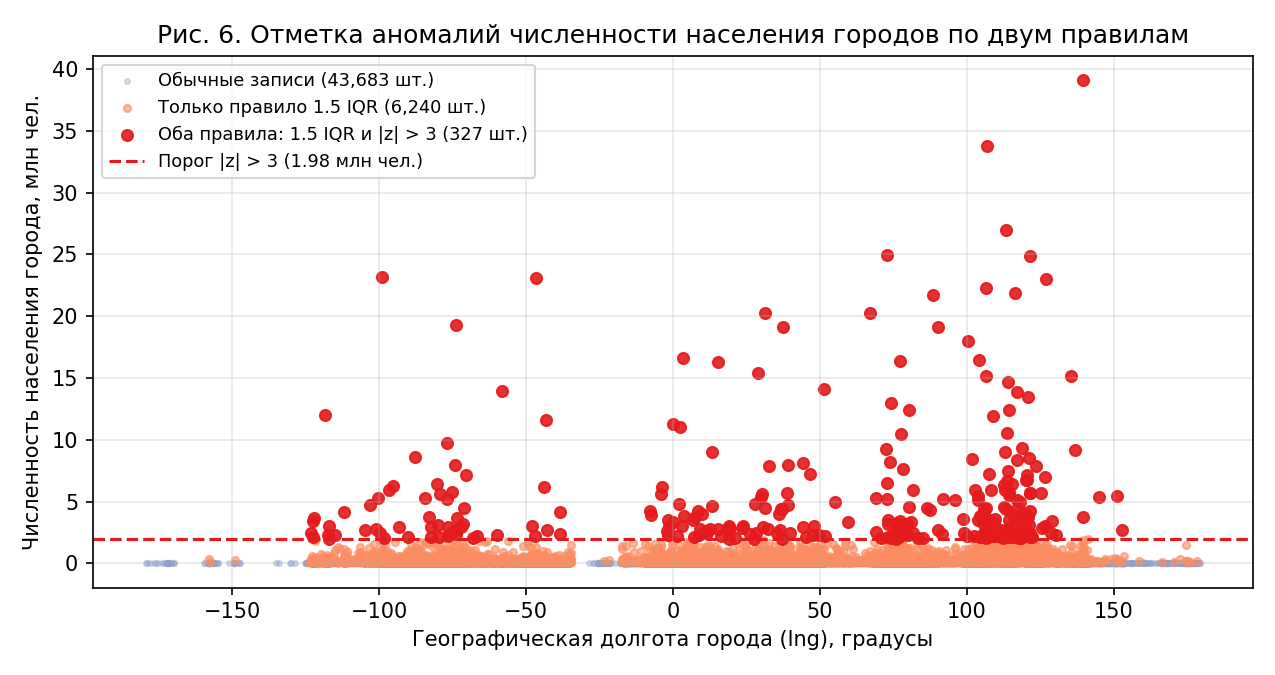

In [ ]:
display(Image(filename="../plots/06_anomalies.png"))

**Вывод по рисунку 6 (Отметка аномалий):** На правоскошенном распределении межквартильное правило `1.5 IQR` отсекает `6 567` городов (`13.07%` выборки) с населением выше `94.2` тыс. чел., относя к выбросам обычные средние города, тогда как правило `|z| > 3` выделяет ровно `327` крупнейших мегаполисов мира (свыше `1.98` млн чел., полностью входящих в список IQR) с наибольшей концентрацией в восточном полушарии (`lng` от `60°` до `140°` в. д. — Индия, Китай, Япония).